# AEGIS AI — Layer 1: Flood Prediction Engine (local Jupyter version)

**Put these files in the SAME folder as this notebook:** `AEGIS_DATA_layer1__1_.xlsx` (or any `AEGIS_DATA_layer1*.xlsx`).

**Output:** `layer1_output.csv` — one row per district (all 30 districts) for ONE forecast date, so Layer 2 can split a limited resource pool across several districts.

Run top-to-bottom (Kernel → Restart & Run All).

In [ ]:
# Run once (remove the leading # if a library is missing)
# %pip install -q xgboost lightgbm openpyxl scikit-learn matplotlib seaborn

In [ ]:
import glob, os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.dummy import DummyClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    precision_recall_curve
)

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

sns.set_style("whitegrid")

print("Libraries loaded successfully.")

Libraries loaded successfully.


In [ ]:
# ============================================================
# CONFIGURATION  (everything you may want to change is here)
# ============================================================
# Folder with your files. "." = the folder this notebook is in.
BASE_DIR = "."

# Excel dataset. The first match of this pattern is used.
DATA_PATTERN = "AEGIS_DATA_layer1*.xlsx"

# Output file read by Layer 2
OUTPUT_FILE = "layer1_output.csv"

# Forecast scenario date (the day the forecast is made; flood is predicted for the NEXT day).
#   None         -> automatically pick the 2025 date on which the model flags the most districts
#   "2025-08-15" -> use exactly this date (must exist in the data, any year is allowed)
SCENARIO_DATE = None

# Replace raw model probabilities with calibrated probabilities (recommended - see section 12)
USE_CALIBRATION = True

# Percent_Flooded_Area is NOT in your Excel file. Unless you supply real values
# (optional file district_static_info.csv, see section 13) it is estimated within this range:
PCT_FLOODED_MIN = 5.0
PCT_FLOODED_MAX = 30.0

# Optional file with real values: columns District, Percent_Flooded_Area, Historical_Fatalities (any subset)
STATIC_INFO_FILE = "district_static_info.csv"

In [ ]:
#3  Locate the dataset (Google Drive code removed)
matches = sorted(glob.glob(os.path.join(BASE_DIR, DATA_PATTERN)))
assert matches, (f"No file matching {DATA_PATTERN} found in {os.path.abspath(BASE_DIR)}. "
                 "Put the Excel file in the same folder as this notebook.")
file_path = matches[0]
print("Using:", file_path)

Using: .\AEGIS_DATA_layer1 (1).xlsx


In [ ]:
#4  Load (the first load of a 20 MB Excel file takes 1-2 minutes)
df = pd.read_excel(file_path)

print("Dataset loaded successfully.")
print("Shape:", df.shape)

Dataset loaded successfully.
Shape: (284910, 13)


In [ ]:
#5

print("Columns:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

Columns:
['Date', 'District', 'State', 'Rainfall_mm', 'Temperature_C', 'Wind_Speed_kmh', 'Soil_Moisture_pct', 'River_Discharge_m3s', 'Water_Level_m', 'Population', 'DFSI_Score', 'Risk_Score', 'Flood_Occurred']

First 5 rows:


,Date,District,State,Rainfall_mm,Temperature_C,Wind_Speed_kmh,Soil_Moisture_pct,River_Discharge_m3s,Water_Level_m,Population,DFSI_Score,Risk_Score,Flood_Occurred
0,36526,Guwahati,ASSAM,0.0,14.05,6.73,77.0,110.0,1.5,1116257.0,18.5,26.65,0
1,36527,Guwahati,ASSAM,0.0,13.72,6.73,77.0,110.0,1.5,1116257.0,18.5,26.65,0
2,36528,Guwahati,ASSAM,0.0,14.13,6.73,77.0,110.0,1.5,1116257.0,18.5,26.65,0
3,36529,Guwahati,ASSAM,0.0,14.10,5.83,77.0,110.0,1.5,NaN,18.5,26.65,0
4,36530,Guwahati,ASSAM,0.0,14.65,5.47,77.0,110.0,1.5,1116257.0,18.5,26.65,0


In [ ]:
#6
if pd.api.types.is_numeric_dtype(df["Date"]):
    df["Date"] = pd.to_datetime(
        df["Date"],
        unit="D",
        origin="1899-12-30"
    )
else:
    df["Date"] = pd.to_datetime(
        df["Date"],
        errors="coerce"
    )

print("Date range:")
print(df["Date"].min(), "to", df["Date"].max())

Date range:
2000-01-01 00:00:00 to 2025-12-31 00:00:00


In [ ]:
#7

TARGET = "Flood_Occurred"

# Remove completely duplicated rows
before = len(df)

df = df.drop_duplicates().copy()

after = len(df)

print("Duplicate rows removed:", before - after)

# Remove rows with invalid dates
df = df.dropna(subset=["Date", TARGET]).copy()

# Make target integer
df[TARGET] = df[TARGET].astype(int)

print("Final shape:", df.shape)

Duplicate rows removed: 0
Final shape: (284910, 13)


In [ ]:
#8

print("Flood target distribution:")
print(df[TARGET].value_counts())

print("\nFlood percentage:")
print(
    (df[TARGET].value_counts(normalize=True) * 100)
    .round(3)
)

Flood target distribution:
Flood_Occurred
0    279108
1      5802
Name: count, dtype: int64

Flood percentage:
Flood_Occurred
0    97.964
1     2.036
Name: proportion, dtype: float64


In [ ]:
#9

print("Number of districts:", df["District"].nunique())
print("Number of states:", df["State"].nunique())

print("\nSample districts:")
print(df["District"].unique()[:10])

print("\nDuplicate District + Date combinations:")
print(
    df.duplicated(
        subset=["District", "Date"]
    ).sum()
)

# Tidy names: "ASSAM" -> "Assam", strip spaces (needed so Layer 2 can match states/districts)
df["State"] = df["State"].astype(str).str.strip().str.title()
df["District"] = df["District"].astype(str).str.strip()

# Population is constant per district: fill the few missing values from the same district
# (the global median used by the pipeline would be wrong for a district)
df["Population"] = df.groupby("District")["Population"].transform(lambda s: s.fillna(s.median()))
print("Missing Population after district-wise fill:", df["Population"].isna().sum())

Number of districts: 30
Number of states: 10

Sample districts:
['Guwahati' 'Dhemaji' 'Silchar' 'Lakhimpur' 'Barpeta' 'Patna' 'Darbhanga'
 'Muzaffarpur' 'Bhagalpur' 'Saharsha']

Duplicate District + Date combinations:
0
Missing Population after district-wise fill: 0


In [ ]:
#10

df = (
    df
    .sort_values(["District", "Date"])
    .reset_index(drop=True)
)

print("Data sorted by District and Date.")

Data sorted by District and Date.


In [ ]:
#11

target_next_day = df[
    ["District", "Date", "Flood_Occurred"]
].copy()

target_next_day["Date"] = (
    target_next_day["Date"]
    - pd.Timedelta(days=1)
)

target_next_day = target_next_day.rename(
    columns={
        "Flood_Occurred": "Flood_Next_Day"
    }
)

df = df.merge(
    target_next_day,
    on=["District", "Date"],
    how="left"
)

print("Future target created.")
print(df["Flood_Next_Day"].value_counts(dropna=False))

Future target created.
Flood_Next_Day
0.0    279078
1.0      5802
NaN        30
Name: count, dtype: int64


In [ ]:
#12

lag_features = [
    "Rainfall_mm",
    "Temperature_C",
    "Wind_Speed_kmh",
    "Soil_Moisture_pct",
    "River_Discharge_m3s",
    "Water_Level_m"
]

lag_days = [1, 3, 7]

for feature in lag_features:

    for lag in lag_days:

        lag_table = df[
            ["District", "Date", feature]
        ].copy()

        lag_table["Date"] = (
            lag_table["Date"]
            + pd.Timedelta(days=lag)
        )

        lag_table = lag_table.rename(
            columns={
                feature: f"{feature}_lag_{lag}"
            }
        )

        df = df.merge(
            lag_table[
                [
                    "District",
                    "Date",
                    f"{feature}_lag_{lag}"
                ]
            ],
            on=["District", "Date"],
            how="left"
        )

print("Lag features created.")

Lag features created.


In [ ]:
#13

for window in [3, 7]:

    rainfall_history = df[
        ["District", "Date", "Rainfall_mm"]
    ].copy()

    rainfall_history = (
        rainfall_history
        .sort_values(["District", "Date"])
    )

    rainfall_history[f"Rainfall_{window}day_mean"] = (
        rainfall_history
        .groupby("District")["Rainfall_mm"]
        .transform(
            lambda x:
            x.shift(1)
             .rolling(window=window, min_periods=1)
             .mean()
        )
    )

    rainfall_history[f"Rainfall_{window}day_max"] = (
        rainfall_history
        .groupby("District")["Rainfall_mm"]
        .transform(
            lambda x:
            x.shift(1)
             .rolling(window=window, min_periods=1)
             .max()
        )
    )

    df = df.merge(
        rainfall_history[
            [
                "District",
                "Date",
                f"Rainfall_{window}day_mean",
                f"Rainfall_{window}day_max"
            ]
        ],
        on=["District", "Date"],
        how="left"
    )

print("Historical rainfall features created.")

Historical rainfall features created.


In [ ]:
#14

df["Year"] = df["Date"].dt.year
df["Month"] = df["Date"].dt.month
df["DayOfYear"] = df["Date"].dt.dayofyear

# Cyclic representation of month
df["Month_Sin"] = np.sin(
    2 * np.pi * df["Month"] / 12
)

df["Month_Cos"] = np.cos(
    2 * np.pi * df["Month"] / 12
)

print(
    df[
        [
            "Date",
            "Year",
            "Month",
            "Month_Sin",
            "Month_Cos"
        ]
    ].head()
)

        Date  Year  Month  Month_Sin  Month_Cos
0 2000-01-01  2000      1        0.5   0.866025
1 2000-01-02  2000      1        0.5   0.866025
2 2000-01-03  2000      1        0.5   0.866025
3 2000-01-04  2000      1        0.5   0.866025
4 2000-01-05  2000      1        0.5   0.866025


In [ ]:
#15

required_columns = [
    "Flood_Next_Day"
]

for feature in lag_features:

    for lag in lag_days:

        required_columns.append(
            f"{feature}_lag_{lag}"
        )

required_columns += [
    "Rainfall_3day_mean",
    "Rainfall_3day_max",
    "Rainfall_7day_mean",
    "Rainfall_7day_max"
]

before = len(df)

df_model = df.dropna(
    subset=required_columns
).copy()

after = len(df_model)

print("Rows before feature preparation:", before)
print("Rows after feature preparation :", after)
print("Rows removed                    :", before - after)

Rows before feature preparation: 284910
Rows after feature preparation : 284534
Rows removed                    : 376


In [ ]:
#16

df_model["Flood_Next_Day"] = (
    df_model["Flood_Next_Day"]
    .astype(int)
)

print(
    df_model["Flood_Next_Day"]
    .value_counts()
)

print("\nTarget percentage:")
print(
    df_model["Flood_Next_Day"]
    .value_counts(normalize=True) * 100
)

Flood_Next_Day
0    278735
1      5799
Name: count, dtype: int64

Target percentage:
Flood_Next_Day
0    97.961931
1     2.038069
Name: proportion, dtype: float64


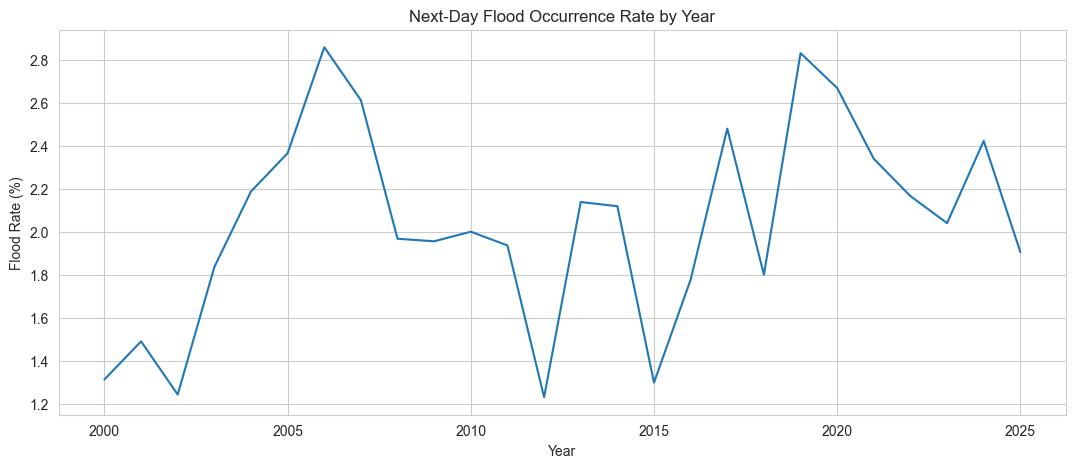

In [ ]:
#17

yearly_rate = (
    df_model
    .groupby("Year")["Flood_Next_Day"]
    .mean()
    * 100
)

plt.figure(figsize=(13, 5))

yearly_rate.plot()

plt.title(
    "Next-Day Flood Occurrence Rate by Year"
)

plt.xlabel("Year")
plt.ylabel("Flood Rate (%)")

plt.show()

In [ ]:
#18

train_df = df_model[
    df_model["Year"] <= 2022
].copy()

validation_df = df_model[
    df_model["Year"].isin([2023, 2024])
].copy()

test_df = df_model[
    df_model["Year"] == 2025
].copy()

print("TRAIN      :", train_df.shape)
print("VALIDATION :", validation_df.shape)
print("TEST       :", test_df.shape)

print("\nTraining years:")
print(train_df["Year"].min(), "-", train_df["Year"].max())

print("\nValidation years:")
print(
    validation_df["Year"].min(),
    "-",
    validation_df["Year"].max()
)

print("\nTest year:")
print(test_df["Year"].unique())

TRAIN      : (251705, 41)
VALIDATION : (21912, 41)
TEST       : (10917, 41)

Training years:
2000 - 2022

Validation years:
2023 - 2024

Test year:
[2025]


In [ ]:
#19

print(
    "Training flood rate:",
    round(
        train_df["Flood_Next_Day"].mean() * 100,
        3
    ),
    "%"
)

print(
    "Validation flood rate:",
    round(
        validation_df["Flood_Next_Day"].mean() * 100,
        3
    ),
    "%"
)

print(
    "Test flood rate:",
    round(
        test_df["Flood_Next_Day"].mean() * 100,
        3
    ),
    "%"
)

Training flood rate: 2.027 %
Validation flood rate: 2.232 %
Test flood rate: 1.905 %


In [ ]:
#20

features = [
    # Current weather/hydrological conditions
    "Rainfall_mm",
    "Temperature_C",
    "Wind_Speed_kmh",
    "Soil_Moisture_pct",
    "River_Discharge_m3s",
    "Water_Level_m",
    "Population",

    # Historical rainfall
    "Rainfall_mm_lag_1",
    "Rainfall_mm_lag_3",
    "Rainfall_mm_lag_7",

    # Historical temperature
    "Temperature_C_lag_1",
    "Temperature_C_lag_3",
    "Temperature_C_lag_7",

    # Historical wind
    "Wind_Speed_kmh_lag_1",
    "Wind_Speed_kmh_lag_3",
    "Wind_Speed_kmh_lag_7",

    # Historical soil moisture
    "Soil_Moisture_pct_lag_1",
    "Soil_Moisture_pct_lag_3",
    "Soil_Moisture_pct_lag_7",

    # Historical river discharge
    "River_Discharge_m3s_lag_1",
    "River_Discharge_m3s_lag_3",
    "River_Discharge_m3s_lag_7",

    # Historical water level
    "Water_Level_m_lag_1",
    "Water_Level_m_lag_3",
    "Water_Level_m_lag_7",

    # Historical rainfall summaries
    "Rainfall_3day_mean",
    "Rainfall_3day_max",
    "Rainfall_7day_mean",
    "Rainfall_7day_max",

    # Calendar
    "Month",
    "DayOfYear",
    "Month_Sin",
    "Month_Cos",

    # Location
    "State",
    "District"
]

TARGET_NEW = "Flood_Next_Day"

X_train = train_df[features]
y_train = train_df[TARGET_NEW]

X_val = validation_df[features]
y_val = validation_df[TARGET_NEW]

X_test = test_df[features]
y_test = test_df[TARGET_NEW]

print("Number of features:", len(features))

Number of features: 35


In [ ]:
#21

numeric_features = [
    feature
    for feature in features
    if feature not in ["State", "District"]
]

categorical_features = [
    "State",
    "District"
]

numeric_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median")
        ),
        (
            "scaler",
            StandardScaler()
        )
    ]
)

categorical_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(
                strategy="most_frequent"
            )
        ),
        (
            "encoder",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=True
            )
        )
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            numeric_transformer,
            numeric_features
        ),
        (
            "cat",
            categorical_transformer,
            categorical_features
        )
    ]
)

print("Preprocessor ready.")

Preprocessor ready.


In [ ]:
#22

baseline = DummyClassifier(
    strategy="most_frequent"
)

baseline.fit(
    X_train,
    y_train
)

baseline_pred = baseline.predict(
    X_test
)

print(
    "Baseline Accuracy:",
    round(
        accuracy_score(
            y_test,
            baseline_pred
        ),
        4
    )
)

print(
    "Baseline Recall:",
    round(
        recall_score(
            y_test,
            baseline_pred,
            zero_division=0
        ),
        4
    )
)

Baseline Accuracy: 0.9809
Baseline Recall: 0.0


In [ ]:
#23

negative_count = (
    y_train == 0
).sum()

positive_count = (
    y_train == 1
).sum()

scale_pos_weight = (
    negative_count / positive_count
)

print("Negative samples:", negative_count)
print("Positive samples:", positive_count)

print(
    "Scale Pos Weight:",
    round(scale_pos_weight, 3)
)

Negative samples: 246603
Positive samples: 5102
Scale Pos Weight: 48.335


In [ ]:
#24

logistic_model = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "model",
            LogisticRegression(
                class_weight="balanced",
                max_iter=1000,
                C=0.5,
                random_state=42
            )
        )
    ]
)

print("Training Logistic Regression...")

logistic_model.fit(
    X_train,
    y_train
)

print("Logistic Regression complete.")

Training Logistic Regression...
Logistic Regression complete.


In [ ]:
#25


rf_model = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "model",
            RandomForestClassifier(
                n_estimators=180,
                max_depth=12,
                min_samples_leaf=8,
                max_features="sqrt",
                class_weight="balanced",
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

print("Training Random Forest...")

rf_model.fit(
    X_train,
    y_train
)

print("Random Forest complete.")

Training Random Forest...
Random Forest complete.


In [ ]:
#26

xgb_model = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "model",
            XGBClassifier(
                n_estimators=180,
                max_depth=4,
                learning_rate=0.04,
                subsample=0.80,
                colsample_bytree=0.80,
                min_child_weight=8,
                reg_alpha=0.2,
                reg_lambda=2.0,
                gamma=0.1,
                scale_pos_weight=scale_pos_weight,
                objective="binary:logistic",
                eval_metric="logloss",
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

print("Training XGBoost...")

xgb_model.fit(
    X_train,
    y_train
)

print("XGBoost complete.")

Training XGBoost...
XGBoost complete.


In [ ]:
#27

lgbm_model = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "model",
            LGBMClassifier(
                n_estimators=180,
                learning_rate=0.04,
                max_depth=6,
                num_leaves=31,
                min_child_samples=50,
                subsample=0.80,
                colsample_bytree=0.80,
                reg_alpha=0.2,
                reg_lambda=2.0,
                class_weight="balanced",
                random_state=42,
                verbosity=-1,
                n_jobs=-1
            )
        )
    ]
)

print("Training LightGBM...")

lgbm_model.fit(
    X_train,
    y_train
)

print("LightGBM complete.")

Training LightGBM...
LightGBM complete.


In [ ]:
#28

def evaluate_model(
    model,
    X_data,
    y_data,
    model_name,
    threshold=0.5
):

    probabilities = model.predict_proba(
        X_data
    )[:, 1]

    predictions = (
        probabilities >= threshold
    ).astype(int)

    return {
        "Model": model_name,

        "Accuracy": accuracy_score(
            y_data,
            predictions
        ),

        "Precision": precision_score(
            y_data,
            predictions,
            zero_division=0
        ),

        "Recall": recall_score(
            y_data,
            predictions,
            zero_division=0
        ),

        "F1 Score": f1_score(
            y_data,
            predictions,
            zero_division=0
        ),

        "ROC-AUC": roc_auc_score(
            y_data,
            probabilities
        ),

        "PR-AUC": average_precision_score(
            y_data,
            probabilities
        )
    }

In [ ]:
#29

models = {
    "Logistic Regression": logistic_model,
    "Random Forest": rf_model,
    "XGBoost": xgb_model,
    "LightGBM": lgbm_model
}

validation_results = []

for name, model in models.items():

    result = evaluate_model(
        model=model,
        X_data=X_val,
        y_data=y_val,
        model_name=name
    )

    validation_results.append(result)

validation_results_df = (
    pd.DataFrame(validation_results)
    .sort_values(
        by="PR-AUC",
        ascending=False
    )
    .reset_index(drop=True)
)

display(
    validation_results_df.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1 Score": "{:.4f}",
        "ROC-AUC": "{:.4f}",
        "PR-AUC": "{:.4f}"
    })
)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
0,XGBoost,0.8414,0.1158,0.9202,0.2057,0.9483,0.3630
1,LightGBM,0.8528,0.1216,0.8998,0.2143,0.9485,0.3614
2,Random Forest,0.9068,0.1643,0.7771,0.2712,0.9454,0.3587
3,Logistic Regression,0.8569,0.1226,0.8793,0.2153,0.9396,0.3042


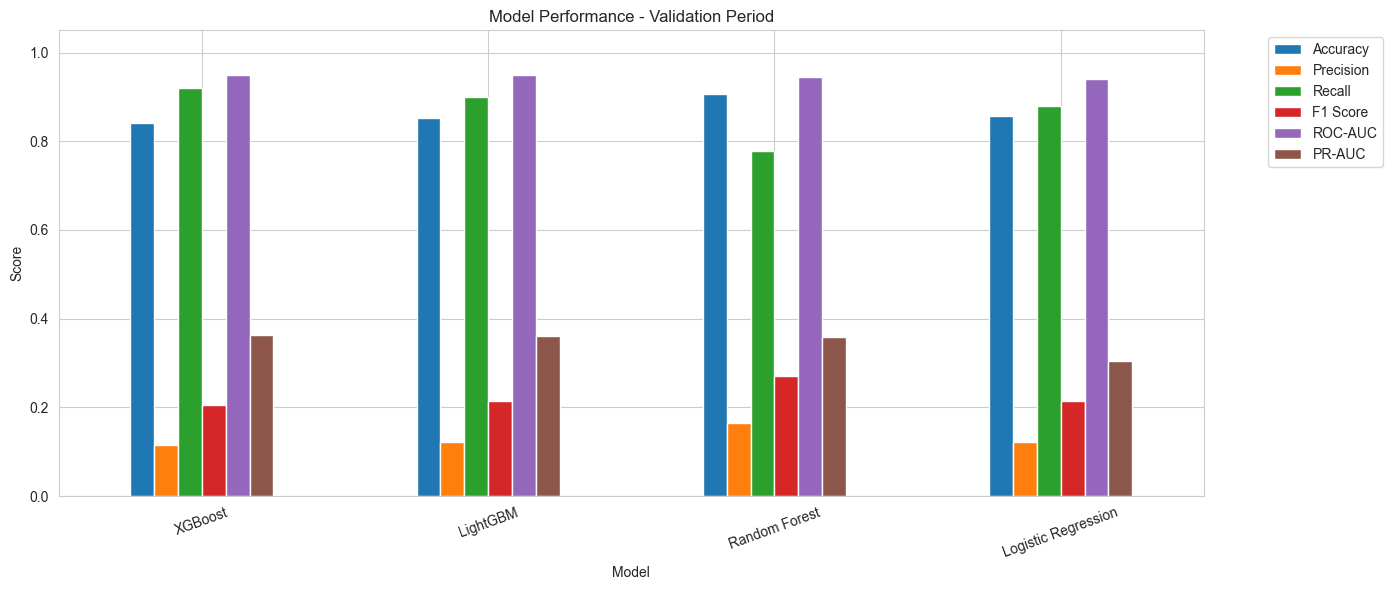

In [ ]:
#30

metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score",
    "ROC-AUC",
    "PR-AUC"
]

validation_results_df.set_index(
    "Model"
)[metrics].plot(
    kind="bar",
    figsize=(14, 6)
)

plt.title(
    "Model Performance - Validation Period"
)

plt.ylabel("Score")
plt.ylim(0, 1.05)

plt.xticks(rotation=20)

plt.legend(
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

In [ ]:
#31

best_model_name = (
    validation_results_df
    .iloc[0]["Model"]
)

best_model = models[
    best_model_name
]

print(
    "Champion model:",
    best_model_name
)

Champion model: XGBoost


In [ ]:
#32

val_probabilities = (
    best_model
    .predict_proba(X_val)[:, 1]
)

thresholds = np.arange(
    0.10,
    0.91,
    0.01
)

threshold_results = []

for threshold in thresholds:

    predictions = (
        val_probabilities >= threshold
    ).astype(int)

    threshold_results.append({

        "Threshold": threshold,

        "Precision": precision_score(
            y_val,
            predictions,
            zero_division=0
        ),

        "Recall": recall_score(
            y_val,
            predictions,
            zero_division=0
        ),

        "F1": f1_score(
            y_val,
            predictions,
            zero_division=0
        )
    })

threshold_df = pd.DataFrame(
    threshold_results
)

best_threshold = (
    threshold_df
    .loc[
        threshold_df["F1"].idxmax(),
        "Threshold"
    ]
)

print(
    "Best validation threshold:",
    round(best_threshold, 2)
)

Best validation threshold: 0.89


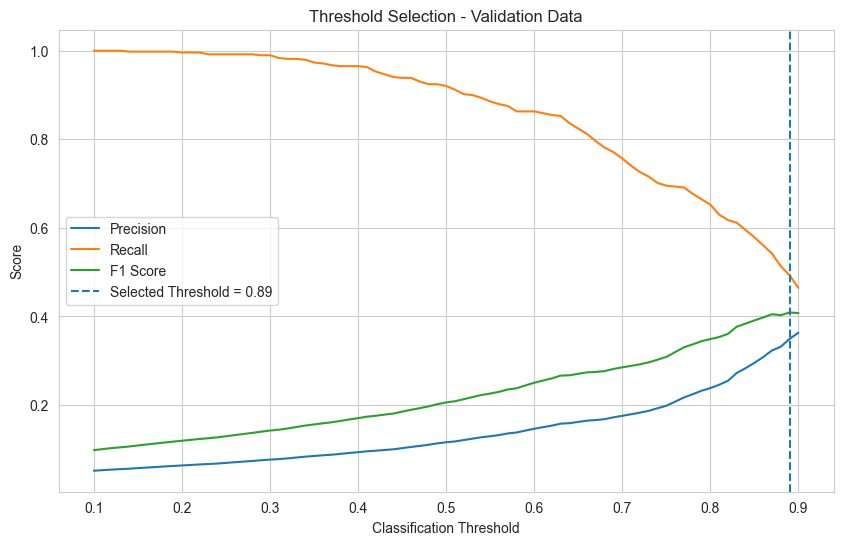

In [ ]:
#33

plt.figure(figsize=(10, 6))

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Precision"],
    label="Precision"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Recall"],
    label="Recall"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["F1"],
    label="F1 Score"
)

plt.axvline(
    best_threshold,
    linestyle="--",
    label=(
        f"Selected Threshold = "
        f"{best_threshold:.2f}"
    )
)

plt.xlabel("Classification Threshold")
plt.ylabel("Score")

plt.title(
    "Threshold Selection - Validation Data"
)

plt.legend()

plt.show()

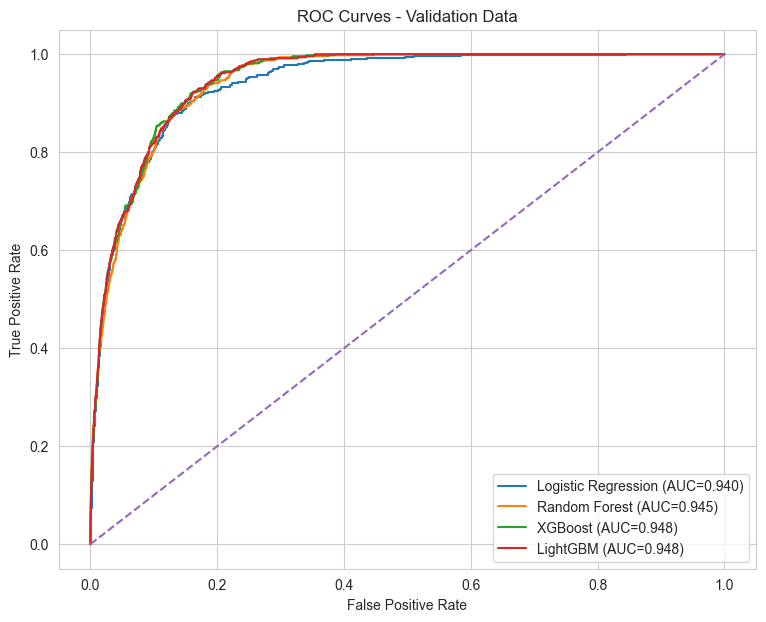

In [ ]:
#34

plt.figure(figsize=(9, 7))

for name, model in models.items():

    probabilities = (
        model.predict_proba(X_val)[:, 1]
    )

    fpr, tpr, _ = roc_curve(
        y_val,
        probabilities
    )

    auc_score = roc_auc_score(
        y_val,
        probabilities
    )

    plt.plot(
        fpr,
        tpr,
        label=f"{name} (AUC={auc_score:.3f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title(
    "ROC Curves - Validation Data"
)

plt.legend()

plt.show()

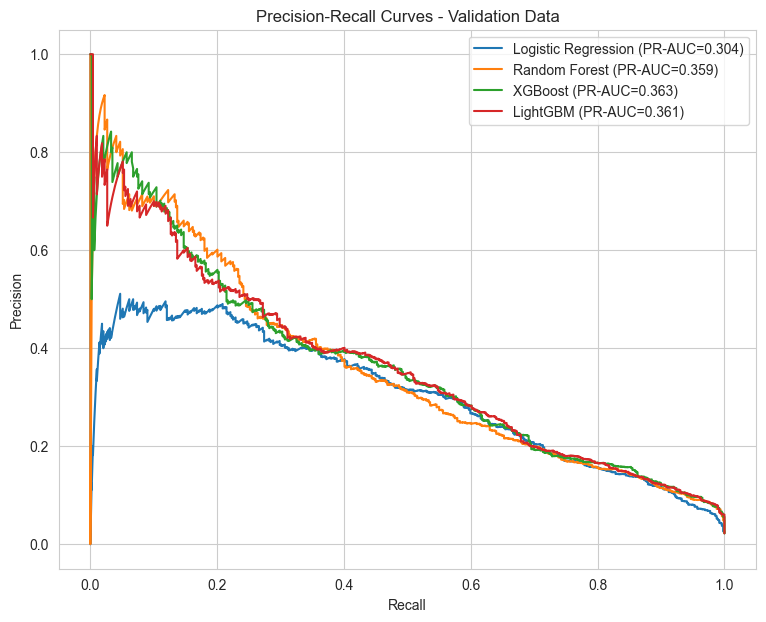

In [ ]:
#35

plt.figure(figsize=(9, 7))

for name, model in models.items():

    probabilities = (
        model.predict_proba(X_val)[:, 1]
    )

    precision, recall, _ = (
        precision_recall_curve(
            y_val,
            probabilities
        )
    )

    pr_auc = (
        average_precision_score(
            y_val,
            probabilities
        )
    )

    plt.plot(
        recall,
        precision,
        label=f"{name} (PR-AUC={pr_auc:.3f})"
    )

plt.xlabel("Recall")
plt.ylabel("Precision")

plt.title(
    "Precision-Recall Curves - Validation Data"
)

plt.legend()

plt.show()

In [ ]:
#36

test_probabilities = (
    best_model
    .predict_proba(X_test)[:, 1]
)

test_predictions = (
    test_probabilities >= best_threshold
).astype(int)

print(
    "2025 test predictions generated."
)

2025 test predictions generated.


In [ ]:
#37

final_accuracy = accuracy_score(
    y_test,
    test_predictions
)

final_precision = precision_score(
    y_test,
    test_predictions,
    zero_division=0
)

final_recall = recall_score(
    y_test,
    test_predictions,
    zero_division=0
)

final_f1 = f1_score(
    y_test,
    test_predictions,
    zero_division=0
)

final_roc_auc = roc_auc_score(
    y_test,
    test_probabilities
)

final_pr_auc = average_precision_score(
    y_test,
    test_probabilities
)

final_results = pd.DataFrame({

    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "ROC-AUC",
        "PR-AUC"
    ],

    "2025 Test Score": [

        final_accuracy,

        final_precision,

        final_recall,

        final_f1,

        final_roc_auc,

        final_pr_auc
    ]
})

display(
    final_results.style.format({
        "2025 Test Score": "{:.4f}"
    })
)

,Metric,2025 Test Score
0,Accuracy,0.9646
1,Precision,0.2555
2,Recall,0.4471
3,F1 Score,0.3252
4,ROC-AUC,0.9259
5,PR-AUC,0.2772


In [ ]:
#38

print(
    classification_report(
        y_test,
        test_predictions,

        target_names=[
            "No Flood",
            "Flood"
        ],

        zero_division=0
    )
)

              precision    recall  f1-score   support

    No Flood       0.99      0.97      0.98     10709
       Flood       0.26      0.45      0.33       208

    accuracy                           0.96     10917
   macro avg       0.62      0.71      0.65     10917
weighted avg       0.98      0.96      0.97     10917



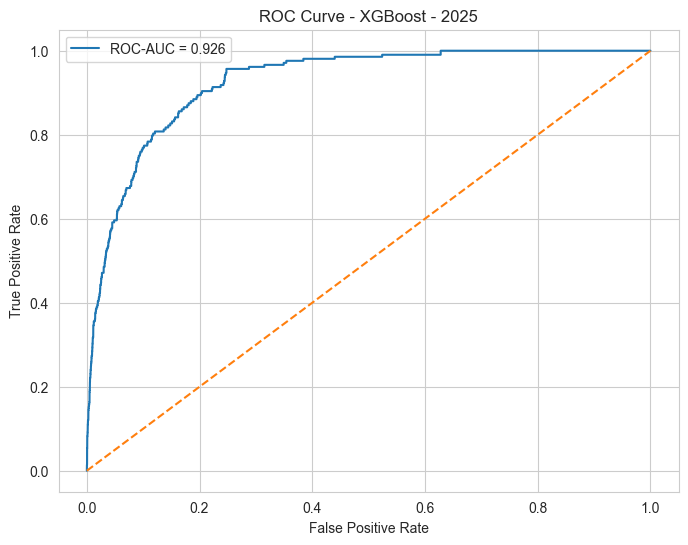

In [ ]:
#40

fpr, tpr, _ = roc_curve(
    y_test,
    test_probabilities
)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f"ROC-AUC = {final_roc_auc:.3f}"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title(
    f"ROC Curve - {best_model_name} - 2025"
)

plt.legend()

plt.show()

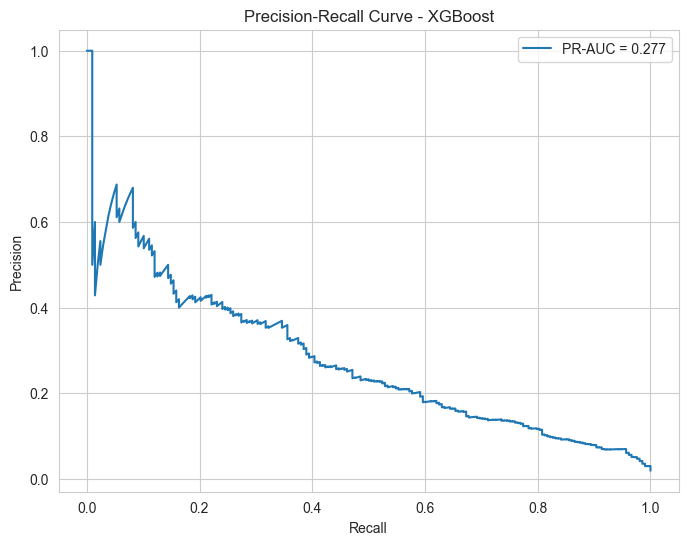

In [ ]:
#41

precision, recall, _ = (
    precision_recall_curve(
        y_test,
        test_probabilities
    )
)

plt.figure(figsize=(8, 6))

plt.plot(
    recall,
    precision,
    label=f"PR-AUC = {final_pr_auc:.3f}"
)

plt.xlabel("Recall")
plt.ylabel("Precision")

plt.title(
    f"Precision-Recall Curve - {best_model_name}"
)

plt.legend()

plt.show()

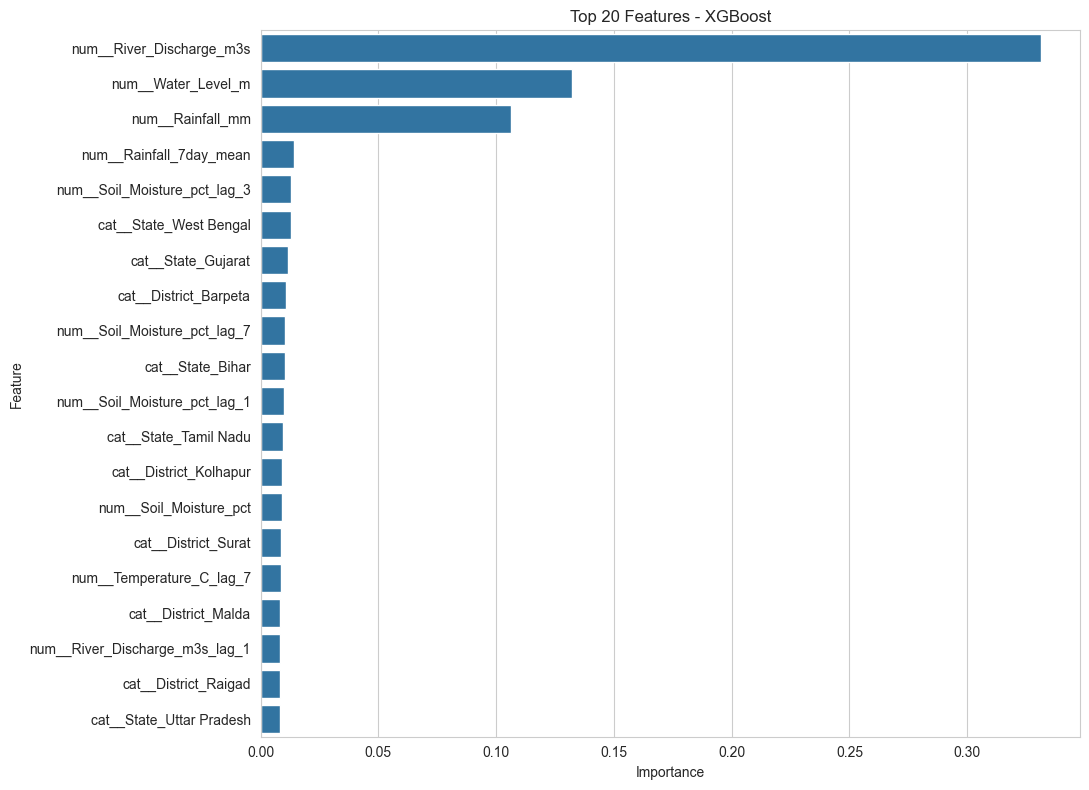

,Feature,Importance
4,num__River_Discharge_m3s,0.331292
5,num__Water_Level_m,0.132096
0,num__Rainfall_mm,0.106166
27,num__Rainfall_7day_mean,0.014407
17,num__Soil_Moisture_pct_lag_3,0.013069
42,cat__State_West Bengal,0.012816
35,cat__State_Gujarat,0.011608
45,cat__District_Barpeta,0.010996
18,num__Soil_Moisture_pct_lag_7,0.010581
34,cat__State_Bihar,0.010536


In [ ]:
#42

if best_model_name in [
    "Random Forest",
    "XGBoost",
    "LightGBM"
]:

    model_step = (
        best_model
        .named_steps["model"]
    )

    prep_step = (
        best_model
        .named_steps["preprocessor"]
    )

    feature_names = (
        prep_step
        .get_feature_names_out()
    )

    importance = (
        model_step
        .feature_importances_
    )

    feature_importance_df = pd.DataFrame({

        "Feature": feature_names,

        "Importance": importance

    })

    feature_importance_df = (
        feature_importance_df
        .sort_values(
            "Importance",
            ascending=False
        )
        .head(20)
    )

    plt.figure(figsize=(11, 8))

    sns.barplot(
        data=feature_importance_df,
        x="Importance",
        y="Feature"
    )

    plt.title(
        f"Top 20 Features - {best_model_name}"
    )

    plt.tight_layout()

    plt.show()

    display(feature_importance_df)

else:

    print(
        "Feature importance chart "
        "is not available for Logistic Regression."
    )

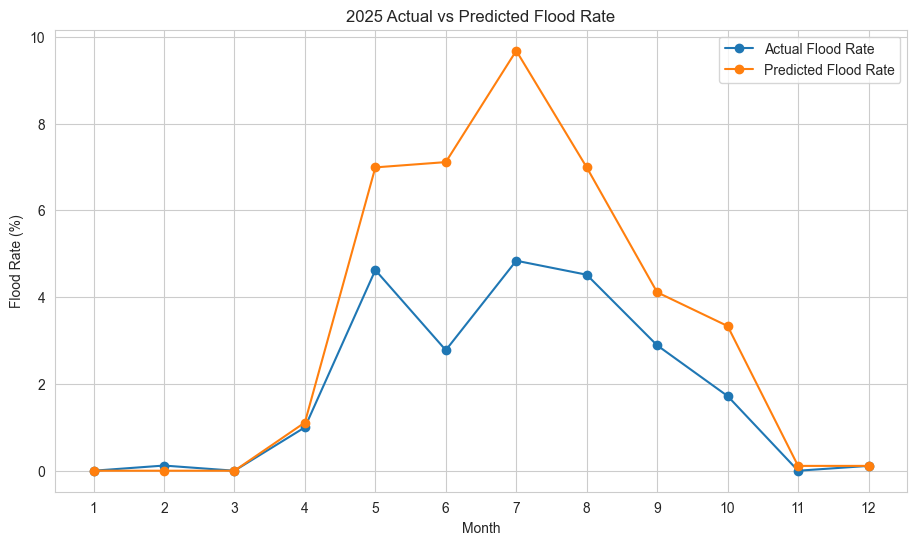

In [ ]:
#43

test_analysis = test_df.copy()

test_analysis["Prediction"] = (
    test_predictions
)

test_analysis["Probability"] = (
    test_probabilities
)

monthly_actual = (
    test_analysis
    .groupby("Month")["Flood_Next_Day"]
    .mean()
    * 100
)

monthly_predicted = (
    test_analysis
    .groupby("Month")["Prediction"]
    .mean()
    * 100
)

plt.figure(figsize=(11, 6))

plt.plot(
    monthly_actual.index,
    monthly_actual.values,
    marker="o",
    label="Actual Flood Rate"
)

plt.plot(
    monthly_predicted.index,
    monthly_predicted.values,
    marker="o",
    label="Predicted Flood Rate"
)

plt.xlabel("Month")
plt.ylabel("Flood Rate (%)")

plt.title(
    "2025 Actual vs Predicted Flood Rate"
)

plt.xticks(range(1, 13))

plt.legend()

plt.show()

In [ ]:
#44

print("=" * 65)
print("                 AEGIS AI")
print("          FLOOD PREDICTION SYSTEM")
print("=" * 65)

print(
    f"Historical Data : "
    f"{df_model['Year'].min()} - "
    f"{df_model['Year'].max()}"
)

print(
    "Training Period  : 2000 - 2022"
)

print(
    "Validation Period: 2023 - 2024"
)

print(
    "Final Test       : 2025"
)

print(
    f"Training Rows    : {len(train_df):,}"
)

print(
    f"Validation Rows  : {len(validation_df):,}"
)

print(
    f"Test Rows        : {len(test_df):,}"
)

print(
    f"Features Used    : {len(features)}"
)

print(
    f"Champion Model   : {best_model_name}"
)

print(
    f"Threshold        : {best_threshold:.2f}"
)

print("\n2025 FINAL TEST PERFORMANCE")
print("-" * 65)

print(
    f"Accuracy  : {final_accuracy:.4f}"
)

print(
    f"Precision : {final_precision:.4f}"
)

print(
    f"Recall    : {final_recall:.4f}"
)

print(
    f"F1 Score  : {final_f1:.4f}"
)

print(
    f"ROC-AUC   : {final_roc_auc:.4f}"
)

print(
    f"PR-AUC    : {final_pr_auc:.4f}"
)

print("=" * 65)

                 AEGIS AI
          FLOOD PREDICTION SYSTEM
Historical Data : 2000 - 2025
Training Period  : 2000 - 2022
Validation Period: 2023 - 2024
Final Test       : 2025
Training Rows    : 251,705
Validation Rows  : 21,912
Test Rows        : 10,917
Features Used    : 35
Champion Model   : XGBoost
Threshold        : 0.89

2025 FINAL TEST PERFORMANCE
-----------------------------------------------------------------
Accuracy  : 0.9646
Precision : 0.2555
Recall    : 0.4471
F1 Score  : 0.3252
ROC-AUC   : 0.9259
PR-AUC    : 0.2772


In [ ]:
#45

def predict_next_day_flood(input_row):
    """
    Predict next-day flood probability.

    input_row must contain all features
    used by the trained model.
    """

    input_df = pd.DataFrame(
        [input_row]
    )

    probability = (
        best_model
        .predict_proba(input_df)[0][1]
    )

    prediction = int(
        probability >= best_threshold
    )

    if probability < 0.25:
        risk = "Low"

    elif probability < 0.50:
        risk = "Moderate"

    elif probability < 0.75:
        risk = "High"

    else:
        risk = "Very High"

    return {
        "Flood Probability (%)":
            round(probability * 100, 2),

        "Prediction":
            (
                "Flood Expected Next Day"
                if prediction == 1
                else "No Flood Expected Next Day"
            ),

        "Risk Level":
            risk
    }

In [ ]:
#46

sample_row = (
    test_df[
        features
    ]
    .iloc[0]
    .to_dict()
)

prediction_result = predict_next_day_flood(
    sample_row
)

print(prediction_result)

{'Flood Probability (%)': np.float32(1.45), 'Prediction': 'No Flood Expected Next Day', 'Risk Level': 'Low'}


## 11. Layer 1 → Layer 2 interface (ALL districts for one date)

The old version produced one district at a time by typing values in by hand. The cells below predict **every district on the same forecast date** and write them to one CSV, so Layer 2 has several districts to compete for the same resource pool.

In [ ]:
# ---- 12. Calibrated probabilities --------------------------------------------
# The models are trained with class weights (scale_pos_weight / class_weight="balanced"),
# which inflates probabilities. Layer 2 MULTIPLIES by the probability to estimate affected
# people, so the numbers must mean what they say. We fit an isotonic calibrator on the
# VALIDATION years (2023-24) only; the test year stays untouched.
from sklearn.isotonic import IsotonicRegression

val_raw = best_model.predict_proba(X_val)[:, 1]
calibrator = IsotonicRegression(out_of_bounds="clip", y_min=0.0, y_max=1.0).fit(val_raw, y_val)

def final_probability(raw):
    raw = np.asarray(raw)
    return calibrator.predict(raw) if USE_CALIBRATION else raw

test_raw = best_model.predict_proba(X_test)[:, 1]
print("Mean predicted prob (raw)        :", round(test_raw.mean(), 4))
print("Mean predicted prob (calibrated) :", round(final_probability(test_raw).mean(), 4))
print("Actual flood rate in 2025 test   :", round(y_test.mean(), 4))
print("Decision threshold (raw scale)   :", round(best_threshold, 2))

Mean predicted prob (raw)        : 0.2339
Mean predicted prob (calibrated) : 0.0244
Actual flood rate in 2025 test   : 0.0191
Decision threshold (raw scale)   : 0.89


In [ ]:
# ---- 13. Static district information (one row per district) -------------------
# Percent_Flooded_Area and Historical_Fatalities do not exist in AEGIS_DATA_layer1.xlsx.
#  * If you have District_FloodedArea / District_FloodImpact, put the numbers in
#    district_static_info.csv (columns: District, Percent_Flooded_Area, Historical_Fatalities)
#    and they will be used.
#  * Otherwise Percent_Flooded_Area is ESTIMATED from the 2000-2022 flood history
#    (how often the district floods + how high the water gets when it does) and scaled to
#    PCT_FLOODED_MIN..PCT_FLOODED_MAX. This is a proxy - state it as an assumption in your report.
#  * Historical_Fatalities is left EMPTY rather than invented (Layer 2 does not use it).
hist = df[df["Year"] <= 2022]
grp = hist.groupby("District")
static = pd.DataFrame({
    "State":      grp["State"].first(),
    "Population": df.groupby("District")["Population"].first(),
    "DFSI_Score": df.groupby("District")["DFSI_Score"].first(),
    "Flood_Freq": grp["Flood_Occurred"].mean(),
    "FloodDay_WaterLevel": hist[hist["Flood_Occurred"] == 1].groupby("District")["Water_Level_m"].mean(),
}).reset_index()

mm = lambda s: (s - s.min()) / (s.max() - s.min() + 1e-9)
hazard = 0.5 * mm(static["Flood_Freq"]) + 0.5 * mm(static["FloodDay_WaterLevel"].fillna(static["FloodDay_WaterLevel"].median()))
static["Percent_Flooded_Area"] = (PCT_FLOODED_MIN + (PCT_FLOODED_MAX - PCT_FLOODED_MIN) * hazard).round(1)
static["Historical_Fatalities"] = np.nan
static["DFSI"] = mm(static["DFSI_Score"]).round(3)       # 0-1, like the Layer 2 template

info_path = os.path.join(BASE_DIR, STATIC_INFO_FILE)
if os.path.exists(info_path):
    info = pd.read_csv(info_path)
    info["District"] = info["District"].astype(str).str.strip()
    for col in ["Percent_Flooded_Area", "Historical_Fatalities"]:
        if col in info.columns:
            static = static.drop(columns=col).merge(info[["District", col]], on="District", how="left")
    print("Loaded real values from", STATIC_INFO_FILE)
else:
    print("No", STATIC_INFO_FILE, "found -> Percent_Flooded_Area is an ESTIMATE.")

display(static[["State", "District", "Population", "DFSI", "Flood_Freq", "Percent_Flooded_Area"]]
        .sort_values("Percent_Flooded_Area", ascending=False).round(3))

No district_static_info.csv found -> Percent_Flooded_Area is an ESTIMATE.


,State,District,Population,DFSI,Flood_Freq,Percent_Flooded_Area
23,Maharashtra,Raigad,2634200.0,0.506,0.057,29.7
27,Gujarat,Surat,6081322.0,0.351,0.038,25.5
25,Assam,Silchar,229136.0,0.662,0.053,19.8
21,Maharashtra,Pune,9429408.0,0.000,0.032,19.5
0,Kerala,Alappuzha,2127652.0,0.740,0.045,19.4
22,Odisha,Puri,1698730.0,0.481,0.019,18.5
8,Kerala,Ernakulam,3282388.0,0.403,0.041,18.1
12,Odisha,Kendrapara,1440289.0,0.779,0.018,17.4
15,Uttar Pradesh,Lakhimpur Kheri,4021243.0,0.701,0.011,16.9
9,Uttar Pradesh,Gorakhpur,4440895.0,0.273,0.014,16.9


In [ ]:
# ---- 14. Severity (probability combined with DFSI, as in the project document) -
# Assumption: a HIGHER DFSI means a district suffers more when it floods.
# composite = probability x (0.75 ... 1.25 depending on normalised DFSI)
def severity_from(prob, dfsi_norm):
    score = np.clip(prob * (0.75 + 0.5 * dfsi_norm), 0, 1)
    return np.select([score < 0.25, score < 0.50, score < 0.75], ["Low", "Medium", "High"], "Critical")

In [ ]:
# ---- 15. Score every district-day that has full lag features --------------------
lag_needed = [c for c in required_columns if c != "Flood_Next_Day"]
pool = df.dropna(subset=lag_needed).copy()          # does not need tomorrow's label
pool["Raw_Prob"] = best_model.predict_proba(pool[features])[:, 1]
pool["Flood_Probability"] = final_probability(pool["Raw_Prob"].values)
pool["Flood_Pred"] = (pool["Raw_Prob"] >= best_threshold).astype(int)

n_districts = df["District"].nunique()
by_day = (pool.groupby("Date")
              .agg(districts=("District", "nunique"), flagged=("Flood_Pred", "sum"),
                   total_prob=("Flood_Probability", "sum"))
              .query("districts == @n_districts"))

if SCENARIO_DATE is None:
    cand = by_day[by_day.index.year == 2025].sort_values(["flagged", "total_prob"], ascending=False)
    scenario_date = cand.index[0]
    print("Auto-selected scenario date (2025 test year, most districts flagged):", scenario_date.date())
    display(cand.head(8))
else:
    scenario_date = pd.Timestamp(SCENARIO_DATE)
    assert scenario_date in by_day.index, f"{SCENARIO_DATE} not available (needs all {n_districts} districts + 7 days of history)"
    print("Using scenario date:", scenario_date.date())

Auto-selected scenario date (2025 test year, most districts flagged): 2025-05-30


,districts,flagged,total_prob
Date,,,
2025-05-30,30,9,3.893968
2025-06-17,30,9,3.186240
2025-05-26,30,8,4.517427
2025-07-26,30,8,3.508883
2025-06-15,30,7,4.029754
2025-05-25,30,7,3.297026
2025-07-14,30,7,3.125372
2025-08-13,30,7,3.057735


In [ ]:
# ---- 16. Build the multi-district Layer 1 output ------------------------------
day = pool[pool["Date"] == scenario_date].merge(
    static[["District", "DFSI", "Percent_Flooded_Area", "Historical_Fatalities"]], on="District", how="left")

day["Severity"] = severity_from(day["Flood_Probability"].values, day["DFSI"].values)
day["Risk_Status"] = np.where(day["Flood_Pred"] == 1, "FLOOD_WARNING", "NORMAL")

layer1_output = pd.DataFrame({
    "District": day["District"],
    "State": day["State"],                              # extra column: avoids same-name districts mixing up
    "Date_Time": day["Date"].dt.strftime("%Y-%m-%d"),
    "Flood_Probability": day["Flood_Probability"].round(4),
    "Flood_Occurred": day["Flood_Pred"],
    "Risk_Status": day["Risk_Status"],
    "Severity": day["Severity"],
    "Percent_Flooded_Area": day["Percent_Flooded_Area"].round(2),
    "Population": day["Population"].astype(int),
    "Historical_Fatalities": day["Historical_Fatalities"],
    "DFSI": day["DFSI"],
}).sort_values("Flood_Probability", ascending=False).reset_index(drop=True)

out_path = os.path.join(BASE_DIR, OUTPUT_FILE)
layer1_output.to_csv(out_path, index=False)

print(f"Saved {len(layer1_output)} districts for {scenario_date.date()} -> {os.path.abspath(out_path)}")
print("Flagged FLOOD_WARNING:", int((layer1_output['Flood_Occurred'] == 1).sum()))
print(layer1_output["Severity"].value_counts().to_string())
display(layer1_output)

Saved 30 districts for 2025-05-30 -> C:\Users\ayush\Music\ML mini project v2\layer1_output.csv
Flagged FLOOD_WARNING: 9
Severity
Low         22
Medium       5
High         2
Critical     1


,District,State,Date_Time,Flood_Probability,Flood_Occurred,Risk_Status,Severity,Percent_Flooded_Area,Population,Historical_Fatalities,DFSI
0,Silchar,Assam,2025-05-30,0.7619,1,FLOOD_WARNING,Critical,19.8,229136,NaN,0.662
1,Guwahati,Assam,2025-05-30,0.6333,1,FLOOD_WARNING,High,15.3,1116257,NaN,0.831
2,Dhemaji,Assam,2025-05-30,0.4194,1,FLOOD_WARNING,High,13.6,686133,NaN,1.000
3,Ernakulam,Kerala,2025-05-30,0.4194,1,FLOOD_WARNING,Medium,18.1,3282388,NaN,0.403
4,Barpeta,Assam,2025-05-30,0.4194,1,FLOOD_WARNING,Medium,16.9,1693622,NaN,0.792
5,Lakhimpur,Assam,2025-05-30,0.3434,1,FLOOD_WARNING,Medium,8.6,1042137,NaN,0.909
6,Alappuzha,Kerala,2025-05-30,0.2922,1,FLOOD_WARNING,Medium,19.4,2127652,NaN,0.740
7,Wayanad,Kerala,2025-05-30,0.2922,1,FLOOD_WARNING,Medium,8.0,817420,NaN,0.558
8,Idukki,Kerala,2025-05-30,0.1753,1,FLOOD_WARNING,Low,11.4,1108974,NaN,0.623
9,Chennai,Tamil Nadu,2025-05-30,0.0277,0,NORMAL,Low,15.8,4646732,NaN,0.532


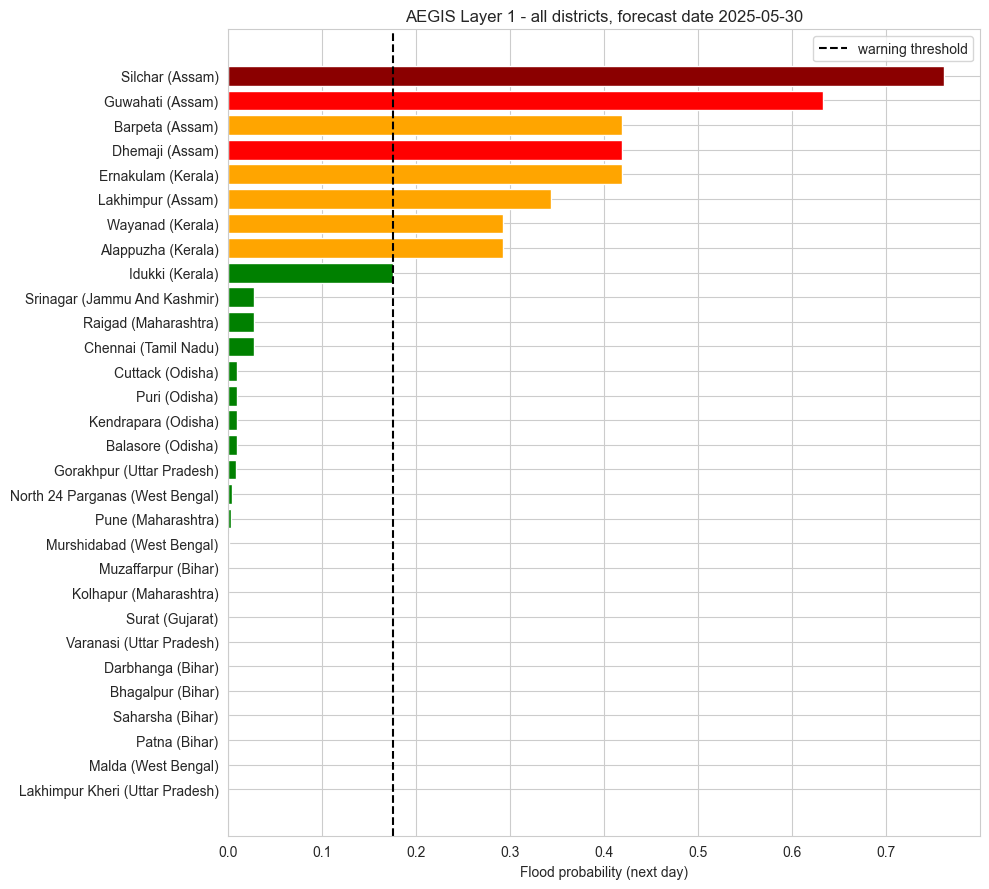

In [ ]:
# ---- 17. Quick look: which districts compete for resources? -------------------
plot_df = layer1_output.sort_values("Flood_Probability")
colors = plot_df["Severity"].map({"Low": "green", "Medium": "orange", "High": "red", "Critical": "darkred"})
plt.figure(figsize=(10, 9))
plt.barh(plot_df["District"] + " (" + plot_df["State"] + ")", plot_df["Flood_Probability"], color=colors)
plt.axvline(final_probability([best_threshold])[0], linestyle="--", color="black", label="warning threshold")
plt.xlabel("Flood probability (next day)")
plt.title(f"AEGIS Layer 1 - all districts, forecast date {scenario_date.date()}")
plt.legend(); plt.tight_layout(); plt.show()